In [1]:
# ============================================================
# 05_results_visualization
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

PROJECT_ROOT = Path(
    "/Users/irfanhussain/Desktop/systemic-risk-project"
)

PROCESSED = (
    PROJECT_ROOT /
    "data" /
    "processed"
)

RESULTS = (
    PROJECT_ROOT /
    "results"
)

RESULTS.mkdir(
    parents=True,
    exist_ok=True
)

print("Processed:", PROCESSED)
print("Results:", RESULTS)

Processed: /Users/irfanhussain/Desktop/systemic-risk-project/data/processed
Results: /Users/irfanhussain/Desktop/systemic-risk-project/results


In [2]:
# ============================================================
# Load final systemic-risk results
# ============================================================

final_systemic = pd.read_csv(
    PROCESSED /
    "final_systemic_risk_baseline_v2.csv"
)

print(
    "Rows:",
    len(final_systemic)
)

print(
    "Columns:",
    final_systemic.columns.tolist()
)

final_systemic.head()

Rows: 300
Columns: ['shocked_bank', 'Financial Institution Name', 'mean_secondary_failures', 'std_secondary_failures', 'mean_total_failed', 'mean_cumulative_loss', 'std_cumulative_loss', 'contagion_score', 'failure_probability', 'total_assets', 'distress_percentile', 'is_mds', 'systemic_risk_score']


,shocked_bank,Financial Institution Name,mean_secondary_failures,std_secondary_failures,mean_total_failed,mean_cumulative_loss,std_cumulative_loss,contagion_score,failure_probability,total_assets,distress_percentile,is_mds,systemic_risk_score
0,210434,"NORTHERN TRUST COMPANY, THE",0.4,0.894427,1.4,3.618409e+07,3.617148e+07,0.945833,0.487829,171309876.0,0.993333,False,0.969583
1,541101,"BANK OF NEW YORK MELLON, THE",0.4,0.547723,1.4,5.182261e+07,5.044657e+07,0.954167,0.139585,398293000.0,0.963333,True,0.958750
2,35301,STATE STREET BANK AND TRUST COMPANY,0.2,0.447214,1.2,5.323244e+07,3.700897e+07,0.937500,0.123504,371784000.0,0.956667,True,0.947083
3,2489805,"MORGAN STANLEY PRIVATE BANK, NATIONAL ASSOCIATION",0.2,0.447214,1.2,1.225043e+07,6.360190e+06,0.889167,0.772845,235034000.0,1.000000,True,0.944583
4,3212149,UBS BANK USA,0.2,0.447214,1.2,1.342468e+07,8.616353e+06,0.895833,0.375422,114294933.0,0.990000,True,0.942917


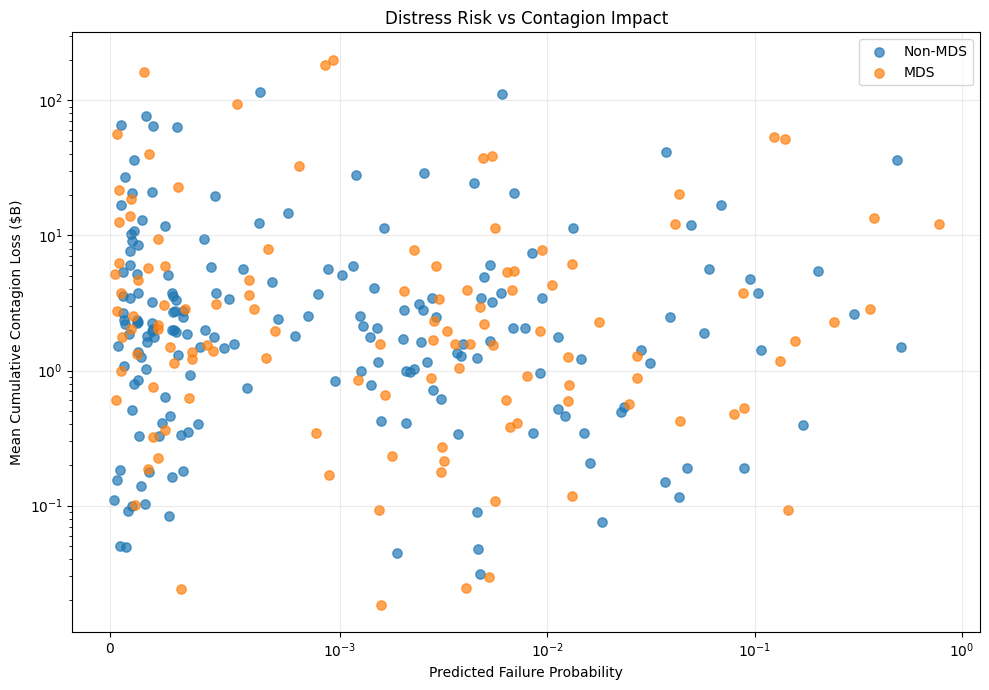

In [6]:
plt.figure(figsize=(10, 7))

for is_mds, group in final_systemic.groupby("is_mds"):
    plt.scatter(
        group["failure_probability"],
        group["mean_cumulative_loss"] / 1e6,   # thousand USD -> billion USD
        label="MDS" if is_mds else "Non-MDS",
        alpha=0.7,
        s=45
    )

plt.xscale("symlog", linthresh=1e-3)
plt.yscale("log")

plt.xlabel("Predicted Failure Probability")
plt.ylabel("Mean Cumulative Contagion Loss ($B)")
plt.title("Distress Risk vs Contagion Impact")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    RESULTS / "distress_vs_contagion.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [7]:
# ============================================================
# Top 20 systemic-risk banks
# ============================================================

top20 = (
    final_systemic
    .sort_values(
        "systemic_risk_score",
        ascending=False
    )
    .head(20)
    .copy()
)

top20[
    [
        "Financial Institution Name",
        "failure_probability",
        "mean_secondary_failures",
        "mean_cumulative_loss",
        "is_mds",
        "systemic_risk_score"
    ]
]

,Financial Institution Name,failure_probability,mean_secondary_failures,mean_cumulative_loss,is_mds,systemic_risk_score
0,"NORTHERN TRUST COMPANY, THE",0.487829,0.4,3.618409e+07,False,0.969583
1,"BANK OF NEW YORK MELLON, THE",0.139585,0.4,5.182261e+07,True,0.958750
2,STATE STREET BANK AND TRUST COMPANY,0.123504,0.2,5.323244e+07,True,0.947083
3,"MORGAN STANLEY PRIVATE BANK, NATIONAL ASSOCIATION",0.772845,0.2,1.225043e+07,True,0.944583
4,UBS BANK USA,0.375422,0.2,1.342468e+07,True,0.942917
5,EAST WEST BANK,0.037375,0.4,4.137991e+07,False,0.924583
6,BANCO POPULAR DE PUERTO RICO,0.068896,0.2,1.686899e+07,False,0.916250
7,"CHARLES SCHWAB BANK, SSB",0.043238,0.2,2.035821e+07,True,0.908750
8,"BANK OF AMERICA, NATIONAL ASSOCIATION",0.006026,2.0,1.116308e+08,False,0.876667
9,U.S. BANK NATIONAL ASSOCIATION,0.005403,0.6,3.839351e+07,True,0.852083


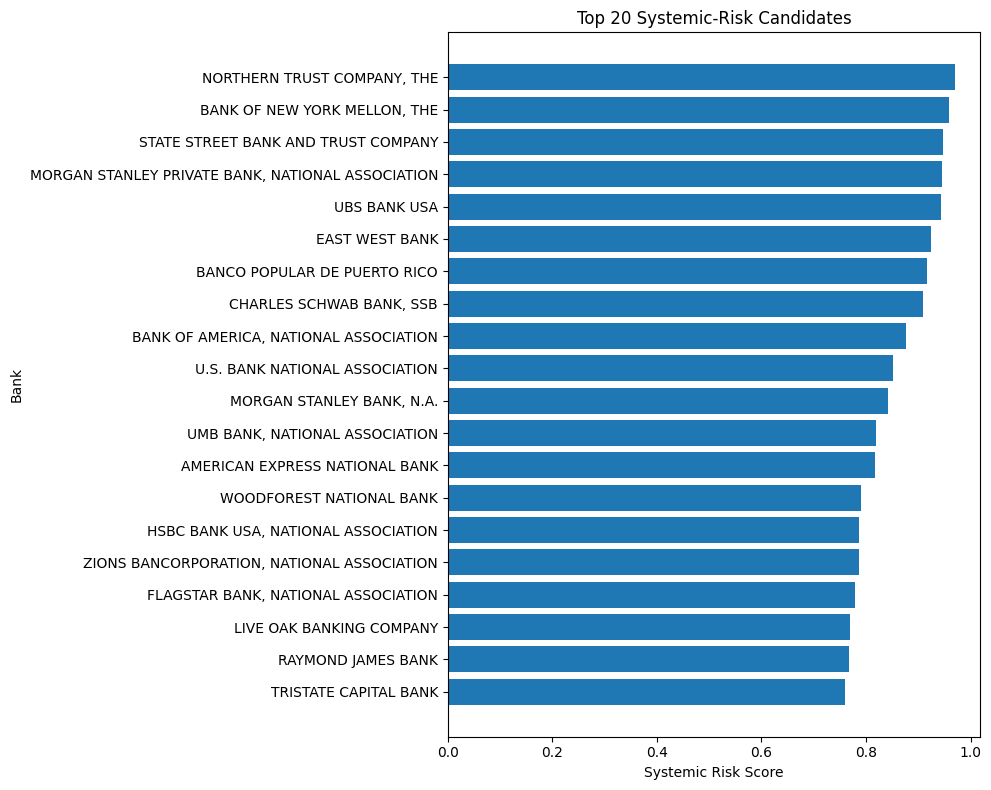

In [8]:
# ============================================================
# Systemic-risk leaderboard
# ============================================================

plot_data = (
    top20
    .sort_values(
        "systemic_risk_score"
    )
)

plt.figure(figsize=(10, 8))

plt.barh(
    plot_data[
        "Financial Institution Name"
    ],
    plot_data[
        "systemic_risk_score"
    ]
)

plt.xlabel(
    "Systemic Risk Score"
)

plt.ylabel(
    "Bank"
)

plt.title(
    "Top 20 Systemic-Risk Candidates"
)

plt.tight_layout()

plt.savefig(
    RESULTS /
    "top20_systemic_risk.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
final_display = final_systemic.copy()

# Display conversions
final_display["failure_probability_pct"] = (
    final_display["failure_probability"] * 100
)

# FFIEC values are in thousands USD -> billion USD
final_display["mean_cumulative_loss_B"] = (
    final_display["mean_cumulative_loss"] / 1e6
)

# Sort by systemic risk
final_display = final_display.sort_values(
    "systemic_risk_score",
    ascending=False
).reset_index(drop=True)

# Add rank
final_display.insert(
    0,
    "Rank",
    np.arange(1, len(final_display) + 1)
)

# Select and rename columns
final_display = final_display[
    [
        "Rank",
        "Financial Institution Name",
        "failure_probability_pct",
        "mean_secondary_failures",
        "mean_cumulative_loss_B",
        "is_mds",
        "systemic_risk_score"
    ]
].copy()

final_display.columns = [
    "Rank",
    "Financial Institution",
    "Failure Probability (%)",
    "Mean Secondary Failures",
    "Mean Cumulative Loss ($B)",
    "mT-MDS",
    "Systemic Risk Score"
]

# Display top 20
final_display.head(20)

,Rank,Financial Institution,Failure Probability (%),Mean Secondary Failures,Mean Cumulative Loss ($B),mT-MDS,Systemic Risk Score
0,1,"NORTHERN TRUST COMPANY, THE",48.782855,0.4,36.184093,False,0.969583
1,2,"BANK OF NEW YORK MELLON, THE",13.958468,0.4,51.822605,True,0.958750
2,3,STATE STREET BANK AND TRUST COMPANY,12.350404,0.2,53.232442,True,0.947083
3,4,"MORGAN STANLEY PRIVATE BANK, NATIONAL ASSOCIATION",77.284500,0.2,12.250435,True,0.944583
4,5,UBS BANK USA,37.542180,0.2,13.424682,True,0.942917
5,6,EAST WEST BANK,3.737469,0.4,41.379908,False,0.924583
6,7,BANCO POPULAR DE PUERTO RICO,6.889588,0.2,16.868991,False,0.916250
7,8,"CHARLES SCHWAB BANK, SSB",4.323835,0.2,20.358214,True,0.908750
8,9,"BANK OF AMERICA, NATIONAL ASSOCIATION",0.602591,2.0,111.630792,False,0.876667
9,10,U.S. BANK NATIONAL ASSOCIATION,0.540332,0.6,38.393506,True,0.852083


In [12]:
final_display.head(20).to_csv(
    RESULTS / "top20_systemic_risk_candidates.csv",
    index=False
)

In [13]:
# ============================================================
# CELL 5 — LOAD mT-MDS NETWORK
# ============================================================

MDS_EDGES = PROCESSED / "mtds_multivariate_edges_rho_080.csv"
MDS_NODES = PROCESSED / "mtds_representatives.parquet"

mds_edges = pd.read_csv(MDS_EDGES)
mds_nodes = pd.read_parquet(MDS_NODES)

print("mT-MDS edges shape:", mds_edges.shape)
print("mT-MDS nodes shape:", mds_nodes.shape)

print("\nEdge columns:")
print(mds_edges.columns.tolist())

print("\nNode columns:")
print(mds_nodes.columns.tolist())

mT-MDS edges shape: (3905, 2)
mT-MDS nodes shape: (117, 33)

Edge columns:
['IDRSSD_1', 'IDRSSD_2']

Node columns:
['IDRSSD', 'FDIC Certificate Number', 'Reporting Period End Date', 'Financial Institution Name', 'Financial Institution State', 'Financial Institution Filing Type', 'total_assets', 'total_equity', 'loans_net_unearned', 'total_nonaccrual', 'total_deposits', 'ytd_net_interest_income', 'ytd_net_income', 'year', 'quarter', 'quarterly_net_interest_income', 'quarterly_net_income', 'capital_ratio', 'loan_to_asset', 'deposit_to_asset', 'nonaccrual_to_loan', 'nonaccrual_to_asset', 'roa', 'nii_to_asset', 'has_nonaccrual', 'quarterly_interest_expense', 'quarterly_interest_income', 'tie_ratio', 'tier1_capital', 't1crc', 'degree', 'is_isolated', 'banks_represented']


In [21]:
# ============================================================
# CELL 6 — BUILD COMPLETE 300-NODE mT-MDS GRAPH
# ============================================================

# IDs appearing in edges = all NON-ISOLATED nodes
edge_node_ids = set(
    mds_edges["IDRSSD_1"]
).union(
    set(mds_edges["IDRSSD_2"])
)

# IDs in mT-MDS representatives = all 117 MDS nodes,
# including the isolated MDS nodes
mds_ids = set(
    pd.to_numeric(
        mtds_nodes["IDRSSD"],
        errors="coerce"
    ).dropna().astype(int)
)

# Complete 300-bank universe
all_node_ids = edge_node_ids.union(mds_ids)

print("Nodes appearing in edges:", len(edge_node_ids))
print("MDS nodes:", len(mds_ids))
print("Total unique nodes:", len(all_node_ids))

# Build graph
G_mtds = nx.Graph()

# Add ALL nodes first
G_mtds.add_nodes_from(all_node_ids)

# Add edges
G_mtds.add_edges_from(
    mds_edges[
        ["IDRSSD_1", "IDRSSD_2"]
    ].itertuples(
        index=False,
        name=None
    )
)

print("\nGraph statistics")
print("-" * 40)
print("Nodes:", G_mtds.number_of_nodes())
print("Edges:", G_mtds.number_of_edges())

Nodes appearing in edges: 216
MDS nodes: 117
Total unique nodes: 300

Graph statistics
----------------------------------------
Nodes: 300
Edges: 3905


In [22]:
# ============================================================
# CELL 7 — ATTACH MDS MEMBERSHIP
# ============================================================

# Every ID in mtds_nodes is an MDS-selected bank
mds_attribute = {
    node: (node in mds_ids)
    for node in G_mtds.nodes
}

nx.set_node_attributes(
    G_mtds,
    mds_attribute,
    "is_mds"
)

print(
    "Total nodes:",
    G_mtds.number_of_nodes()
)

print(
    "MDS nodes:",
    sum(
        G_mtds.nodes[n]["is_mds"]
        for n in G_mtds.nodes
    )
)

print(
    "Non-MDS nodes:",
    sum(
        not G_mtds.nodes[n]["is_mds"]
        for n in G_mtds.nodes
    )
)

Total nodes: 300
MDS nodes: 117
Non-MDS nodes: 183


In [23]:
# ============================================================
# CELL 8 — ATTACH BANK NAMES
# ============================================================

name_map = dict(
    zip(
        pd.to_numeric(
            mtds_nodes["IDRSSD"],
            errors="coerce"
        ).astype(int),
        mtds_nodes["Financial Institution Name"]
    )
)

nx.set_node_attributes(
    G_mtds,
    name_map,
    "name"
)

print(
    "Named nodes:",
    sum(
        "name" in G_mtds.nodes[n]
        for n in G_mtds.nodes
    )
)

Named nodes: 117


In [24]:
# ============================================================
# CELL 9 — VERIFY mT-MDS NETWORK
# ============================================================

degrees = dict(G_mtds.degree())

degree_values = np.array(
    list(degrees.values())
)

num_isolated = sum(
    d == 0 for d in degree_values
)

components = list(
    nx.connected_components(G_mtds)
)

largest_component = max(
    len(c) for c in components
)

print("mT-MDS Network Statistics")
print("-" * 45)
print("Nodes:", G_mtds.number_of_nodes())
print("Edges:", G_mtds.number_of_edges())
print("Density:", nx.density(G_mtds))
print("Isolated nodes:", num_isolated)
print("Connected components:", len(components))
print("Largest component:", largest_component)
print("Average degree:", degree_values.mean())
print("Maximum degree:", degree_values.max())

mT-MDS Network Statistics
---------------------------------------------
Nodes: 300
Edges: 3905
Density: 0.0870680044593088
Isolated nodes: 84
Connected components: 90
Largest component: 182
Average degree: 26.033333333333335
Maximum degree: 95


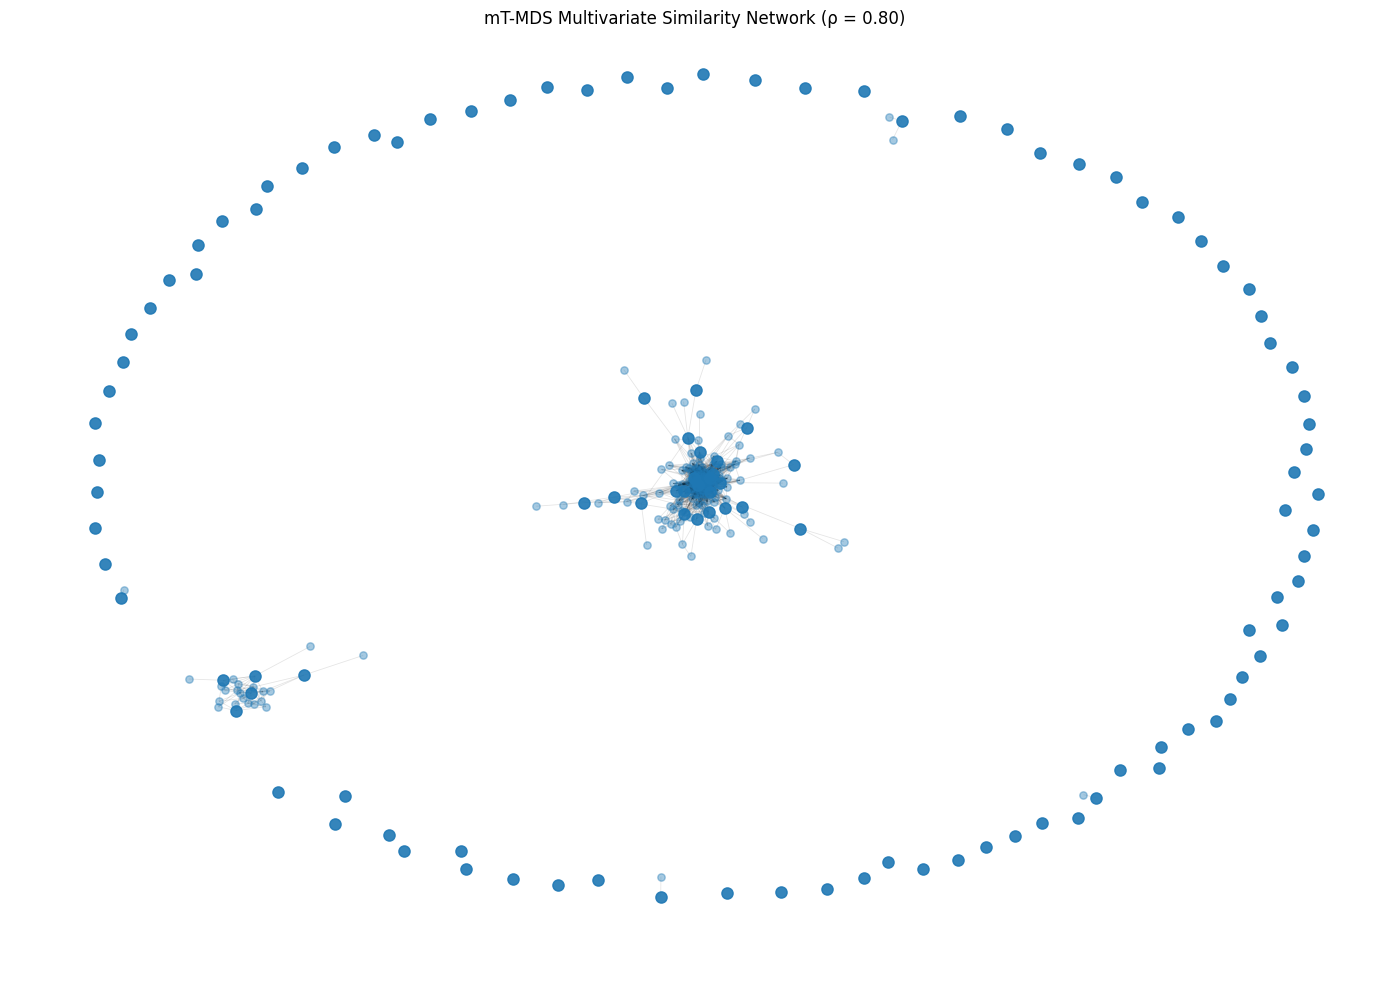

In [25]:
# ============================================================
# CELL 10 — mT-MDS NETWORK VISUALIZATION
# ============================================================

plt.figure(figsize=(14, 10))

pos = nx.spring_layout(
    G_mtds,
    seed=42,
    k=0.22,
    iterations=200
)

mds_nodes_list = [
    n for n in G_mtds.nodes
    if G_mtds.nodes[n]["is_mds"]
]

non_mds_nodes = [
    n for n in G_mtds.nodes
    if not G_mtds.nodes[n]["is_mds"]
]

# Draw edges
nx.draw_networkx_edges(
    G_mtds,
    pos,
    alpha=0.10,
    width=0.6
)

# Non-MDS nodes
nx.draw_networkx_nodes(
    G_mtds,
    pos,
    nodelist=non_mds_nodes,
    node_size=28,
    alpha=0.40
)

# MDS nodes
nx.draw_networkx_nodes(
    G_mtds,
    pos,
    nodelist=mds_nodes_list,
    node_size=65,
    alpha=0.90
)

plt.title(
    "mT-MDS Multivariate Similarity Network (ρ = 0.80)"
)

plt.axis("off")
plt.tight_layout()

plt.savefig(
    RESULTS / "mtds_network_rho_080.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

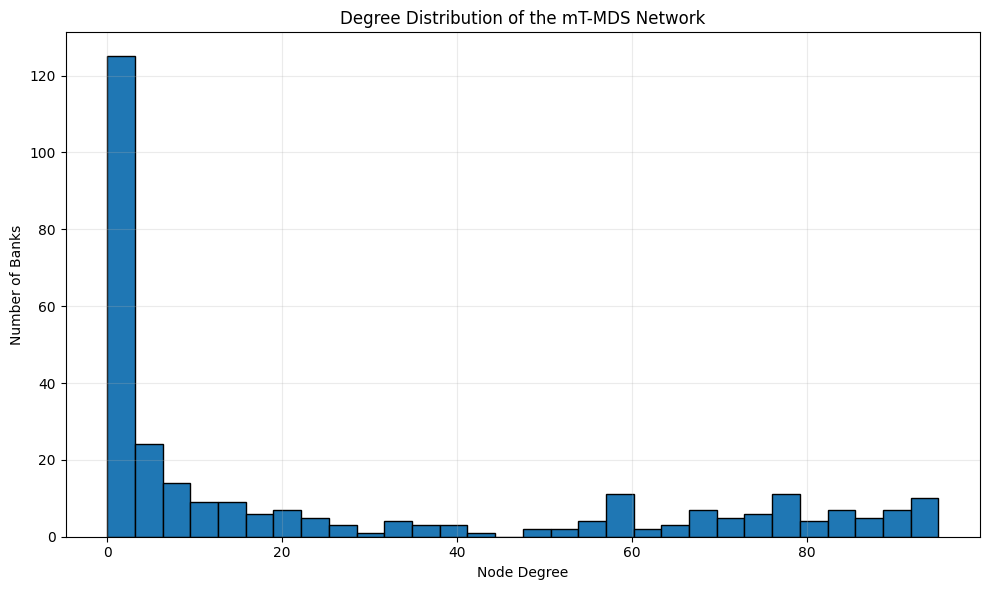

In [26]:
# ============================================================
# CELL 11 — DEGREE DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 6))

plt.hist(
    degree_values,
    bins=30,
    edgecolor="black"
)

plt.xlabel("Node Degree")
plt.ylabel("Number of Banks")
plt.title(
    "Degree Distribution of the mT-MDS Network"
)

plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    RESULTS / "mtds_degree_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Largest connected component:
Nodes: 182
Edges: 3816


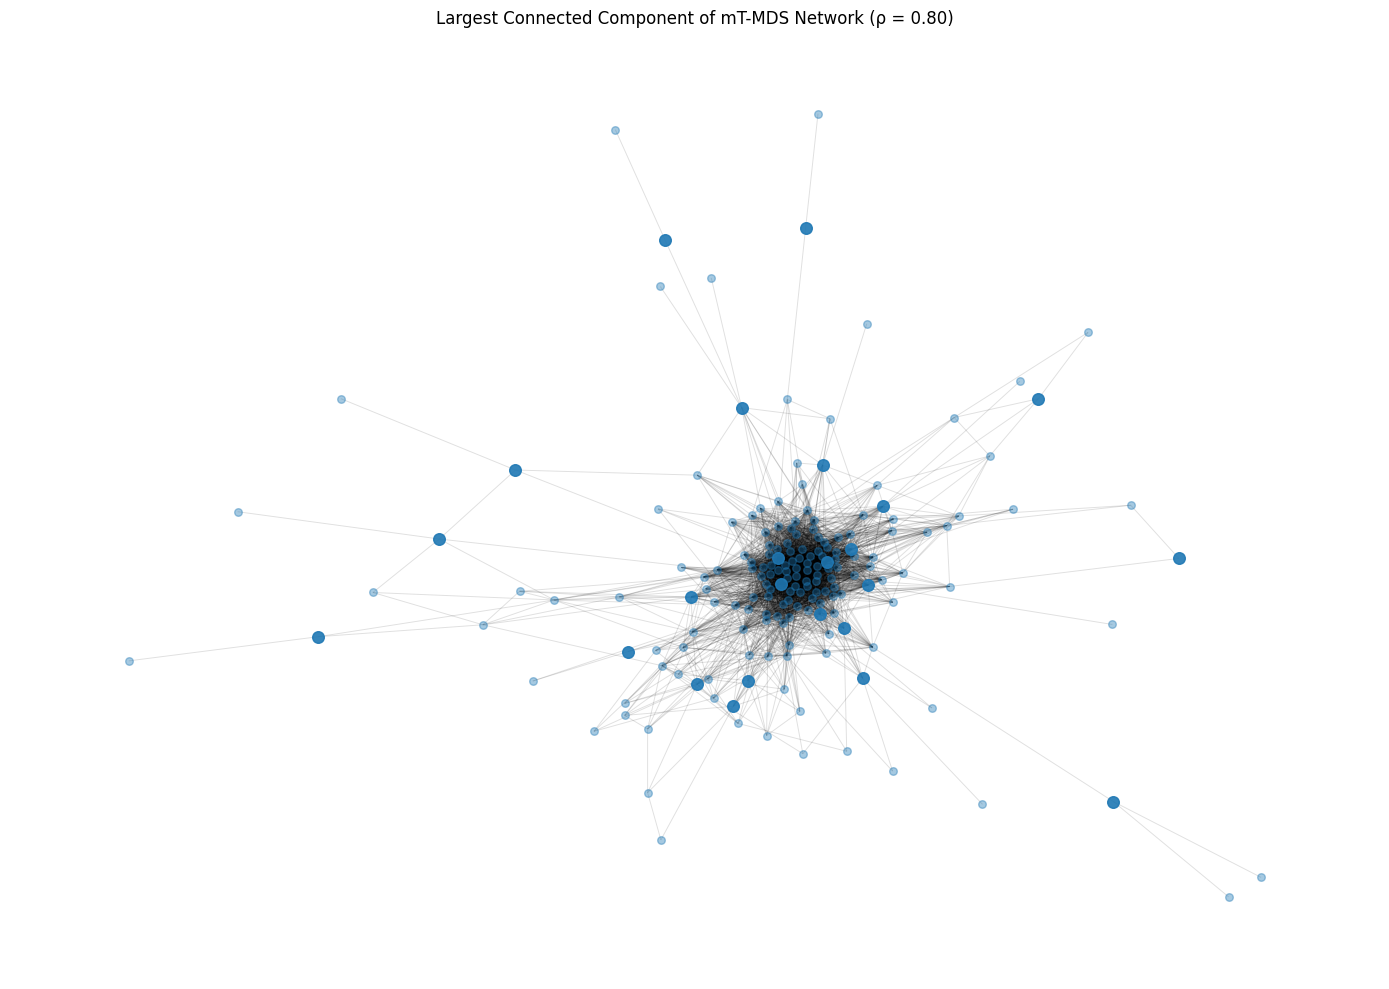

In [27]:
# ============================================================
# CELL 12 — LARGEST CONNECTED COMPONENT
# ============================================================

# Find largest connected component
largest_component_nodes = max(
    nx.connected_components(G_mtds),
    key=len
)

G_core = G_mtds.subgraph(
    largest_component_nodes
).copy()

print("Largest connected component:")
print("Nodes:", G_core.number_of_nodes())
print("Edges:", G_core.number_of_edges())

plt.figure(figsize=(14, 10))

pos_core = nx.spring_layout(
    G_core,
    seed=42,
    k=0.20,
    iterations=250
)

core_mds = [
    n for n in G_core.nodes
    if G_core.nodes[n].get("is_mds", False)
]

core_non_mds = [
    n for n in G_core.nodes
    if not G_core.nodes[n].get("is_mds", False)
]

nx.draw_networkx_edges(
    G_core,
    pos_core,
    alpha=0.12,
    width=0.7
)

nx.draw_networkx_nodes(
    G_core,
    pos_core,
    nodelist=core_non_mds,
    node_size=30,
    alpha=0.40
)

nx.draw_networkx_nodes(
    G_core,
    pos_core,
    nodelist=core_mds,
    node_size=70,
    alpha=0.90
)

plt.title(
    "Largest Connected Component of mT-MDS Network (ρ = 0.80)"
)

plt.axis("off")
plt.tight_layout()

plt.savefig(
    RESULTS / "mtds_largest_component_rho_080.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [28]:
# ============================================================
# CELL 13 — LOAD CONTAGION NETWORK
# ============================================================

CONTAGION_EDGES = (
    PROCESSED /
    "contagion_baseline_edges_seed42.csv"
)

CONTAGION_NODES = (
    PROCESSED /
    "contagion_baseline_nodes.csv"
)

contagion_edges = pd.read_csv(
    CONTAGION_EDGES
)

contagion_nodes = pd.read_csv(
    CONTAGION_NODES
)

print("Contagion edge shape:", contagion_edges.shape)
print("Contagion node shape:", contagion_nodes.shape)

print("\nEdge columns:")
print(contagion_edges.columns.tolist())

print("\nNode columns:")
print(contagion_nodes.columns.tolist())

Contagion edge shape: (1552, 3)
Contagion node shape: (300, 4)

Edge columns:
['source_id', 'target_id', 'exposure_thousand_usd']

Node columns:
['IDRSSD', 'tier1_capital_thousand_usd', 'Financial Institution Name', 'total_assets_thousand_usd']


In [29]:
# ============================================================
# CELL 14 — BUILD DIRECTED CONTAGION GRAPH
# ============================================================

G_contagion = nx.DiGraph()

# Add all 300 banks
G_contagion.add_nodes_from(
    contagion_nodes["IDRSSD"].astype(int)
)

# Add directed exposures
for _, row in contagion_edges.iterrows():

    G_contagion.add_edge(
        int(row["source_id"]),
        int(row["target_id"]),
        exposure=row["exposure_thousand_usd"]
    )

print("Nodes:", G_contagion.number_of_nodes())
print("Edges:", G_contagion.number_of_edges())

print(
    "Average out-degree:",
    np.mean(
        [G_contagion.out_degree(n)
         for n in G_contagion.nodes]
    )
)

print(
    "Maximum out-degree:",
    max(
        dict(G_contagion.out_degree()).values()
    )
)

print(
    "Maximum in-degree:",
    max(
        dict(G_contagion.in_degree()).values()
    )
)

Nodes: 300
Edges: 1552
Average out-degree: 5.173333333333333
Maximum out-degree: 20
Maximum in-degree: 48


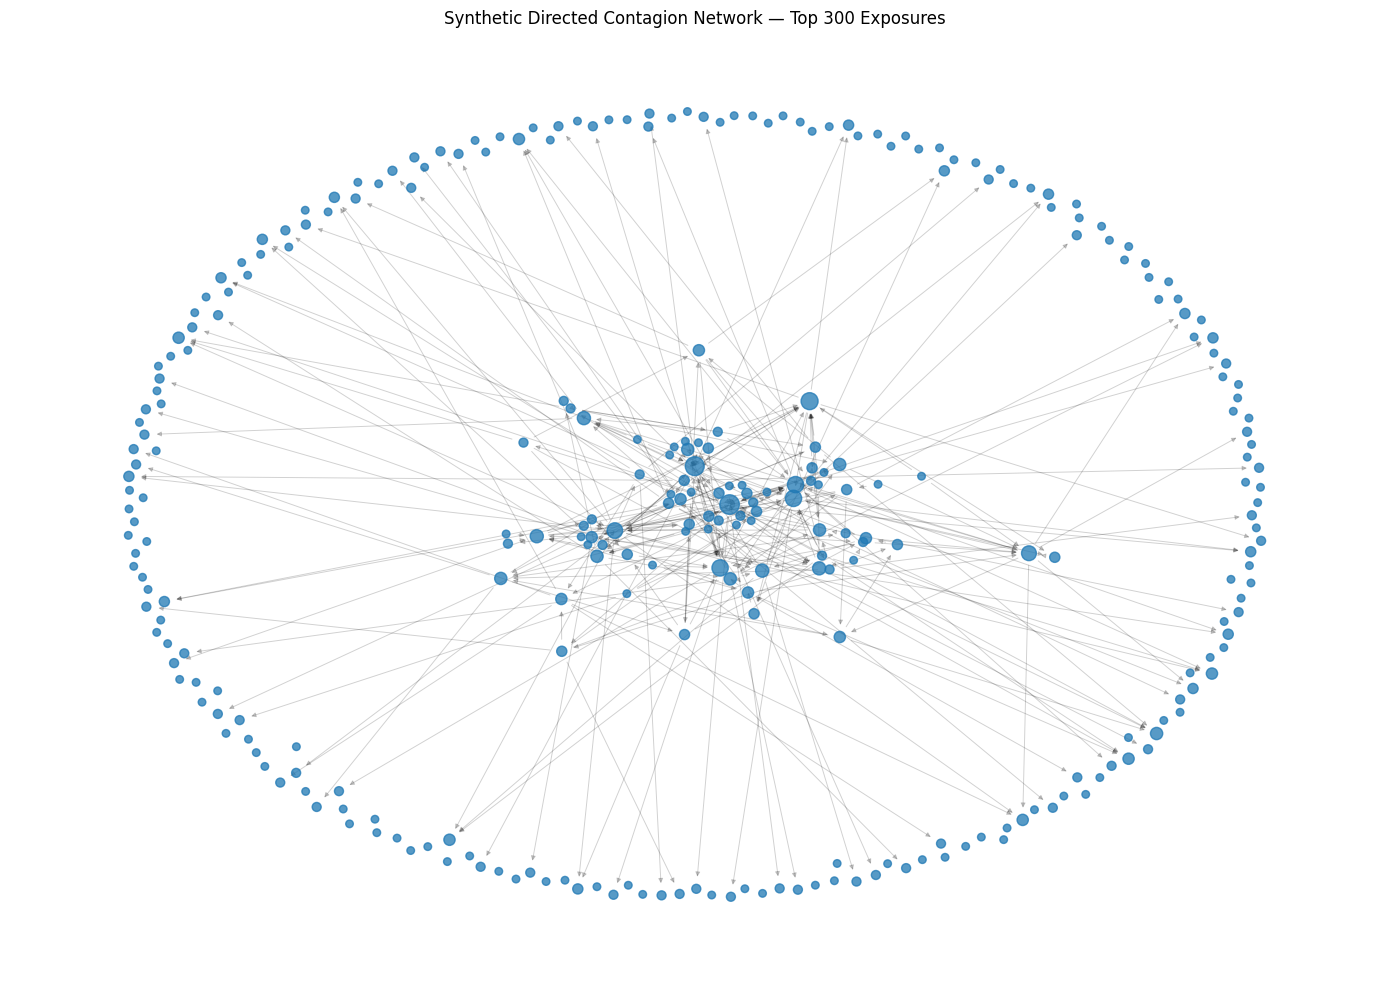

In [30]:
# ============================================================
# CELL 15 — CONTAGION NETWORK VISUALIZATION
# ============================================================

# Keep the strongest 300 directed exposures for readability
top_edges = (
    contagion_edges
    .nlargest(300, "exposure_thousand_usd")
)

G_visual = nx.DiGraph()

G_visual.add_nodes_from(
    contagion_nodes["IDRSSD"].astype(int)
)

for _, row in top_edges.iterrows():

    G_visual.add_edge(
        int(row["source_id"]),
        int(row["target_id"]),
        exposure=row["exposure_thousand_usd"]
    )

# Layout
plt.figure(figsize=(14, 10))

pos = nx.spring_layout(
    G_visual,
    seed=42,
    k=0.25,
    iterations=200
)

# Node sizes based on in-degree
in_degree = dict(G_visual.in_degree())

node_sizes = [
    30 + 12 * in_degree.get(n, 0)
    for n in G_visual.nodes
]

nx.draw_networkx_nodes(
    G_visual,
    pos,
    node_size=node_sizes,
    alpha=0.75
)

nx.draw_networkx_edges(
    G_visual,
    pos,
    alpha=0.18,
    arrows=True,
    arrowsize=7,
    width=0.7
)

plt.title(
    "Synthetic Directed Contagion Network — Top 300 Exposures"
)

plt.axis("off")
plt.tight_layout()

plt.savefig(
    RESULTS / "contagion_network_seed42_top300.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()